In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
%pip install -q -U kaggle

In [4]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle credentials loaded.")

Kaggle credentials loaded.


In [5]:
!kaggle datasets download \
    -d paultimothymooney/chest-xray-pneumonia \
    -p /content

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:13<00:00, 188MB/s]



In [6]:
import os

zip_path = "/content/chest-xray-pneumonia.zip"

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print("Dataset ZIP found!")
    print(f"File size: {size_mb:.2f} MB")
else:
    print("Dataset ZIP not found. Check the download output above.")

Dataset ZIP found!
File size: 2349.25 MB


In [7]:
import zipfile
import os

zip_path = "/content/chest-xray-pneumonia.zip"
extract_path = "/content/chest_xray"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")
print(os.listdir(extract_path))

Extraction complete!
['chest_xray']


In [1]:
import os

for root, dirs, files in os.walk("/content/chest_xray"):
    dirs[:] = sorted(dirs)
    if files:
        print(root, "->", len(files), "files")

In [2]:
import os

base_path = "/content/chest_xray"

for root, dirs, files in os.walk(base_path):
    dirs.sort()
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print(f"{root}: {len(image_files)} images")

In [3]:
import os

base_path = "/content/chest_xray/chest_xray"

for split in ["train", "val", "test"]:
    for category in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(base_path, split, category)

        if os.path.isdir(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            print(f"{split}/{category}: {count} images")
        else:
            print(f"Not found: {folder}")

Not found: /content/chest_xray/chest_xray/train/NORMAL
Not found: /content/chest_xray/chest_xray/train/PNEUMONIA
Not found: /content/chest_xray/chest_xray/val/NORMAL
Not found: /content/chest_xray/chest_xray/val/PNEUMONIA
Not found: /content/chest_xray/chest_xray/test/NORMAL
Not found: /content/chest_xray/chest_xray/test/PNEUMONIA


In [4]:
import os

for root, dirs, files in os.walk("/content/chest_xray"):
    dirs.sort()

    # Show folders and image counts
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images or any(
        name.lower() in ["train", "test", "val", "normal", "pneumonia"]
        for name in dirs
    ):
        print(root)
        if images:
            print("  Images:", len(images))
        if dirs:
            print("  Subfolders:", dirs)

In [5]:
import os

path = "/content/chest_xray"

print("Folder exists:", os.path.exists(path))
print("Folder contents:", os.listdir(path) if os.path.exists(path) else "Not found")
print("Current directory:", os.getcwd())

Folder exists: False
Folder contents: Not found
Current directory: /content


In [6]:
import os

zip_path = "/content/chest-xray-pneumonia.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("Size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))
else:
    print("ZIP file is missing from this runtime.")

ZIP exists: False
ZIP file is missing from this runtime.


In [8]:
%pip install -q -U kaggle

In [9]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle token loaded.")

Kaggle token loaded.


In [10]:
!kaggle datasets download \
    -d paultimothymooney/chest-xray-pneumonia \
    -p /content

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:19<00:00, 127MB/s]



In [11]:
import os
import zipfile

zip_path = "/content/chest-xray-pneumonia.zip"
extract_path = "/content/chest_xray"

if not os.path.exists(zip_path):
    raise FileNotFoundError("Dataset ZIP not found. Run the download cell first.")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")

for root, dirs, files in os.walk(extract_path):
    dirs.sort()
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    if images:
        print(f"{root}: {len(images)} images")

Extraction complete!
/content/chest_xray/chest_xray/__MACOSX/chest_xray/test/NORMAL: 234 images
/content/chest_xray/chest_xray/__MACOSX/chest_xray/test/PNEUMONIA: 390 images
/content/chest_xray/chest_xray/__MACOSX/chest_xray/train/NORMAL: 1341 images
/content/chest_xray/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA: 3875 images
/content/chest_xray/chest_xray/__MACOSX/chest_xray/val/NORMAL: 8 images
/content/chest_xray/chest_xray/__MACOSX/chest_xray/val/PNEUMONIA: 8 images
/content/chest_xray/chest_xray/chest_xray/test/NORMAL: 234 images
/content/chest_xray/chest_xray/chest_xray/test/PNEUMONIA: 390 images
/content/chest_xray/chest_xray/chest_xray/train/NORMAL: 1341 images
/content/chest_xray/chest_xray/chest_xray/train/PNEUMONIA: 3875 images
/content/chest_xray/chest_xray/chest_xray/val/NORMAL: 8 images
/content/chest_xray/chest_xray/chest_xray/val/PNEUMONIA: 8 images
/content/chest_xray/chest_xray/test/NORMAL: 234 images
/content/chest_xray/chest_xray/test/PNEUMONIA: 390 images
/conte

In [12]:
import os
from pathlib import Path

DATA_DIR = Path("/content/chest_xray/chest_xray/chest_xray")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / category

        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{category}: {len(images)} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


In [13]:
from sklearn.model_selection import train_test_split
from pathlib import Path

image_paths = []
labels = []

for category, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    folder = DATA_DIR / "train" / category

    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths.append(str(path))
            labels.append(label)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.1765,
    random_state=42,
    stratify=labels
)

print("New training images:", len(train_paths))
print("New validation images:", len(val_paths))
print("Official test images:", 624)
print("Stratified split created successfully.")

New training images: 4295
New validation images: 921
Official test images: 624
Stratified split created successfully.


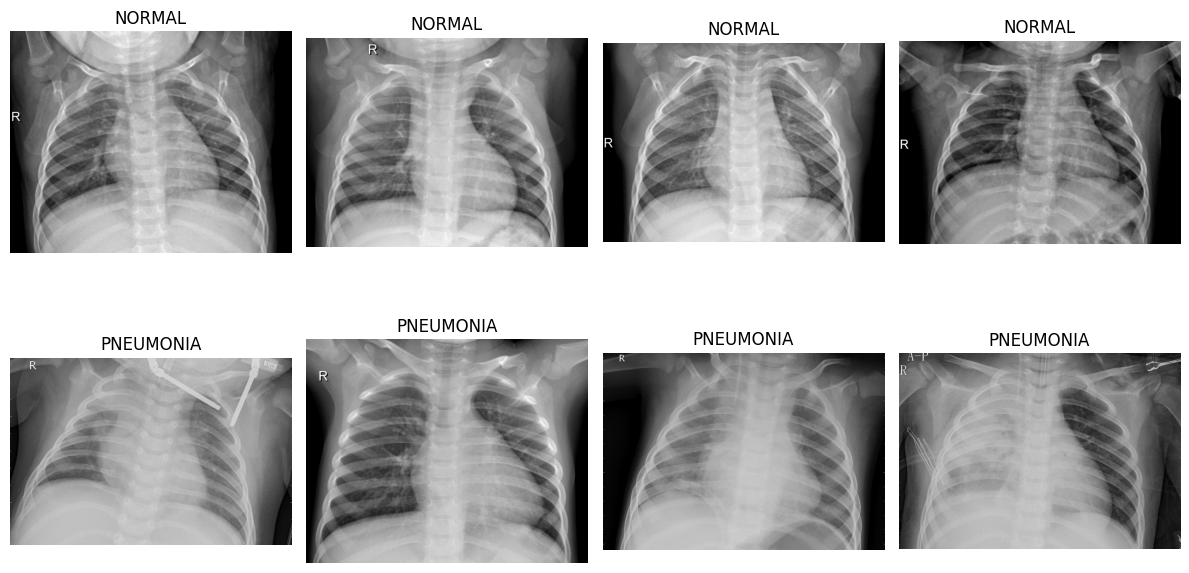

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for row, label in enumerate([0, 1]):
    paths = [
        p for p, y in zip(train_paths, train_labels)
        if y == label
    ]

    for col in range(4):
        img_path = random.choice(paths)
        img = Image.open(img_path).convert("RGB")

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].axis("off")
        axes[row, col].set_title(
            "NORMAL" if label == 0 else "PNEUMONIA"
        )

plt.tight_layout()
plt.show()

In [15]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ChestXrayDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = ChestXrayDataset(
    train_paths, train_labels, train_transform
)

val_dataset = ChestXrayDataset(
    val_paths, val_labels, eval_transform
)

test_paths = []
test_labels = []

for category, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    folder = DATA_DIR / "test" / category

    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            test_paths.append(str(path))
            test_labels.append(label)

test_dataset = ChestXrayDataset(
    test_paths, test_labels, eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Training batches: 135
Validation batches: 29
Test batches: 20


In [16]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CustomCNN().to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", device)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

sample = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    output = model(sample)

print("Output shape:", output.shape)

Device: cuda
Total parameters: 389,890
Trainable parameters: 389,890
Output shape: torch.Size([2, 2])


In [17]:
import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5
best_val_loss = float("inf")
patience = 2
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_model_state)
torch.save(model.state_dict(), "/content/custom_cnn_best.pth")

print("Best model saved.")

Epoch 1/5 | Train Loss: 0.2887 | Train Acc: 0.8731 | Val Loss: 0.2275 | Val Acc: 0.9012
Epoch 2/5 | Train Loss: 0.2377 | Train Acc: 0.8959 | Val Loss: 0.2962 | Val Acc: 0.8686
Epoch 3/5 | Train Loss: 0.2022 | Train Acc: 0.9197 | Val Loss: 0.1667 | Val Acc: 0.9273
Epoch 4/5 | Train Loss: 0.1778 | Train Acc: 0.9290 | Val Loss: 0.2436 | Val Acc: 0.9023
Epoch 5/5 | Train Loss: 0.1504 | Train Acc: 0.9434 | Val Loss: 0.1110 | Val Acc: 0.9566
Best model saved.


In [18]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights=weights)

# Freeze all pretrained backbone parameters
for param in resnet.parameters():
    param.requires_grad = False

# Replace the final classification layer
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, 2)

resnet = resnet.to(device)

print("ResNet-18 loaded successfully.")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in resnet.parameters() if p.requires_grad)
)
print("Output classes: NORMAL, PNEUMONIA")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


ResNet-18 loaded successfully.
Device: cuda
Trainable parameters: 1026
Output classes: NORMAL, PNEUMONIA


In [19]:
import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet.fc.parameters(), lr=0.001)

EPOCHS = 3
best_resnet_loss = float("inf")
best_resnet_state = copy.deepcopy(resnet.state_dict())

resnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    resnet.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    resnet.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = resnet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_resnet_loss:
        best_resnet_loss = val_loss
        best_resnet_state = copy.deepcopy(resnet.state_dict())

resnet.load_state_dict(best_resnet_state)
torch.save(resnet.state_dict(), "/content/resnet18_feature_extractor.pth")

print("Best feature-extractor model saved.")

Epoch 1/3 | Train Loss: 0.2569 | Train Acc: 0.8950 | Val Loss: 0.1906 | Val Acc: 0.9251
Epoch 2/3 | Train Loss: 0.1828 | Train Acc: 0.9269 | Val Loss: 0.1699 | Val Acc: 0.9327
Epoch 3/3 | Train Loss: 0.1603 | Train Acc: 0.9385 | Val Loss: 0.1411 | Val Acc: 0.9446
Best feature-extractor model saved.


In [20]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Start from the best feature-extractor checkpoint
resnet.load_state_dict(best_resnet_state)

# Unfreeze all layers
for param in resnet.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

# Use a smaller learning rate for pretrained weights
optimizer = optim.Adam([
    {"params": resnet.layer1.parameters(), "lr": 1e-5},
    {"params": resnet.layer2.parameters(), "lr": 1e-5},
    {"params": resnet.layer3.parameters(), "lr": 1e-5},
    {"params": resnet.layer4.parameters(), "lr": 1e-5},
    {"params": resnet.fc.parameters(), "lr": 1e-4},
    {"params": resnet.conv1.parameters(), "lr": 1e-5},
    {"params": resnet.bn1.parameters(), "lr": 1e-5}
])

EPOCHS = 3
best_finetune_loss = float("inf")
best_finetune_state = copy.deepcopy(resnet.state_dict())

finetune_history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

for epoch in range(EPOCHS):
    resnet.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    resnet.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = resnet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    finetune_history["train_loss"].append(train_loss)
    finetune_history["val_loss"].append(val_loss)
    finetune_history["train_acc"].append(train_acc)
    finetune_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_finetune_loss:
        best_finetune_loss = val_loss
        best_finetune_state = copy.deepcopy(resnet.state_dict())

resnet.load_state_dict(best_finetune_state)
torch.save(
    resnet.state_dict(),
    "/content/resnet18_finetuned.pth"
)

print("Best fine-tuned ResNet-18 model saved.")

Epoch 1/3 | Train Loss: 0.1025 | Train Acc: 0.9609 | Val Loss: 0.0617 | Val Acc: 0.9805
Epoch 2/3 | Train Loss: 0.0601 | Train Acc: 0.9772 | Val Loss: 0.0482 | Val Acc: 0.9837
Epoch 3/3 | Train Loss: 0.0341 | Train Acc: 0.9909 | Val Loss: 0.0381 | Val Acc: 0.9848
Best fine-tuned ResNet-18 model saved.


In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

def evaluate_model(model, loader, model_name):
    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(outputs.argmax(dim=1).cpu().numpy())
            y_prob.extend(probabilities[:, 1].cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else 0,
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    print(f"\n{'=' * 50}")
    print(model_name)
    print("=" * 50)

    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    ))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["NORMAL", "PNEUMONIA"]
    )
    display.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"AUC = {results['ROC-AUC']:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {model_name}")
    plt.legend()
    plt.show()

    return results


Custom CNN
Accuracy: 0.8077
Sensitivity: 0.9846
Specificity: 0.5128
Precision: 0.7711
F1-score: 0.8649
ROC-AUC: 0.9390

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.95      0.51      0.67       234
   PNEUMONIA       0.77      0.98      0.86       390

    accuracy                           0.81       624
   macro avg       0.86      0.75      0.77       624
weighted avg       0.84      0.81      0.79       624



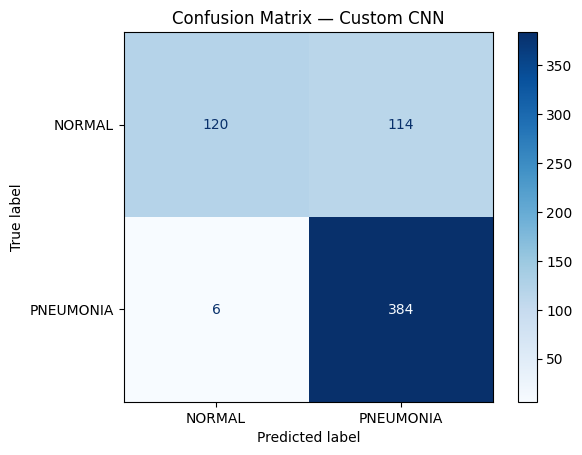

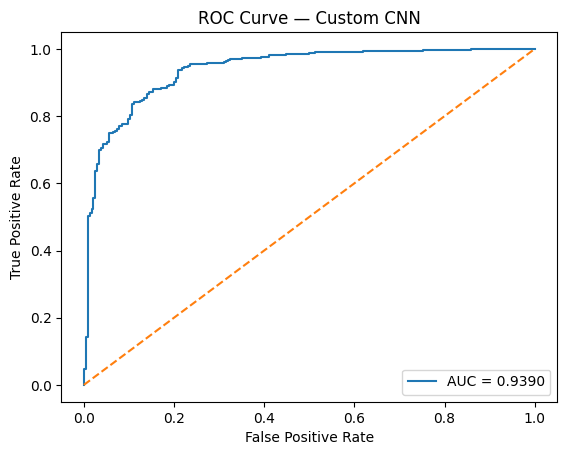

In [22]:
custom_results = evaluate_model(
    model,
    test_loader,
    "Custom CNN"
)


ResNet-18 Feature Extractor
Accuracy: 0.7997
Sensitivity: 0.9821
Specificity: 0.4957
Precision: 0.7645
F1-score: 0.8597
ROC-AUC: 0.9524

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.50      0.65       234
   PNEUMONIA       0.76      0.98      0.86       390

    accuracy                           0.80       624
   macro avg       0.85      0.74      0.75       624
weighted avg       0.83      0.80      0.78       624



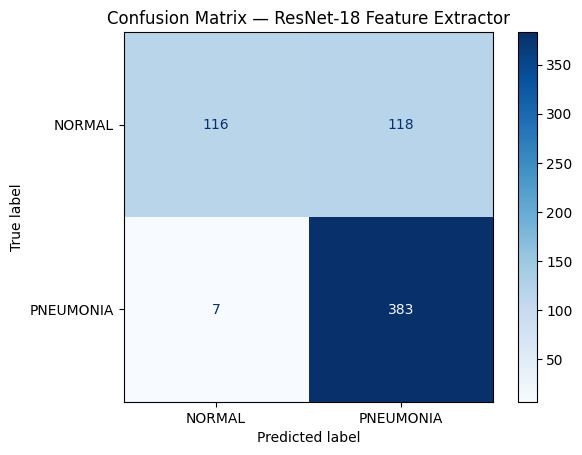

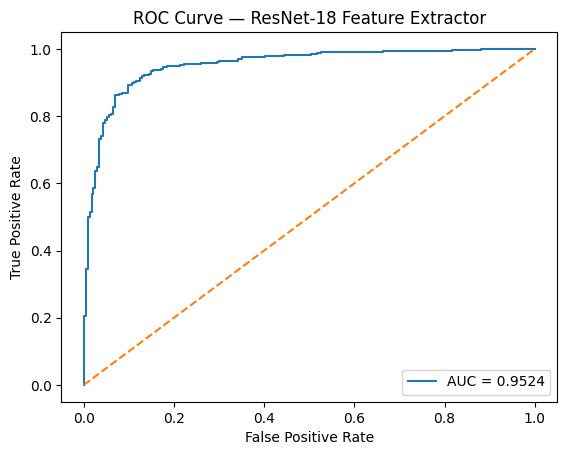

In [23]:
resnet.load_state_dict(
    torch.load(
        "/content/resnet18_feature_extractor.pth",
        map_location=device,
        weights_only=True
    )
)

feature_results = evaluate_model(
    resnet,
    test_loader,
    "ResNet-18 Feature Extractor"
)


ResNet-18 Fine-Tuned
Accuracy: 0.8462
Sensitivity: 0.9897
Specificity: 0.6068
Precision: 0.8075
F1-score: 0.8894
ROC-AUC: 0.9543

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.61      0.75       234
   PNEUMONIA       0.81      0.99      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.80      0.82       624
weighted avg       0.87      0.85      0.84       624



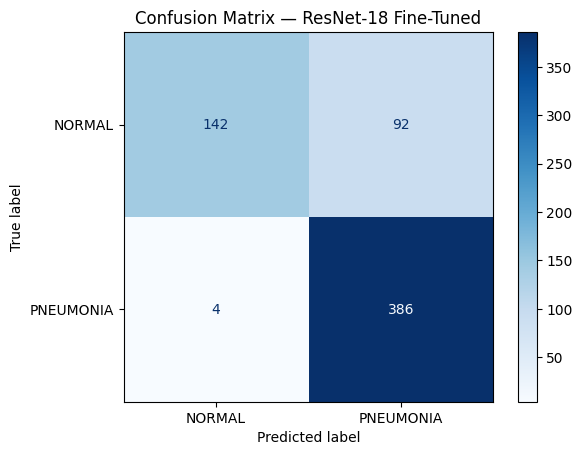

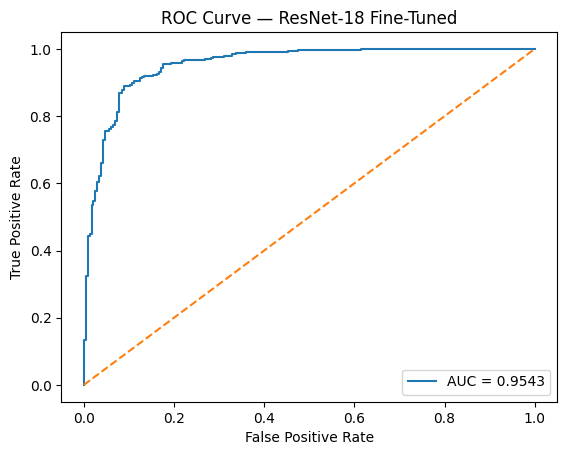

In [24]:
resnet.load_state_dict(
    torch.load(
        "/content/resnet18_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)

finetuned_results = evaluate_model(
    resnet,
    test_loader,
    "ResNet-18 Fine-Tuned"
)

In [25]:
import pandas as pd

results_df = pd.DataFrame([
    custom_results,
    feature_results,
    finetuned_results
])

print(results_df.round(4).to_string(index=False))

                      Model  Accuracy  Sensitivity  Specificity  Precision  F1-score  ROC-AUC
                 Custom CNN    0.8077       0.9846       0.5128     0.7711    0.8649   0.9390
ResNet-18 Feature Extractor    0.7997       0.9821       0.4957     0.7645    0.8597   0.9524
       ResNet-18 Fine-Tuned    0.8462       0.9897       0.6068     0.8075    0.8894   0.9543


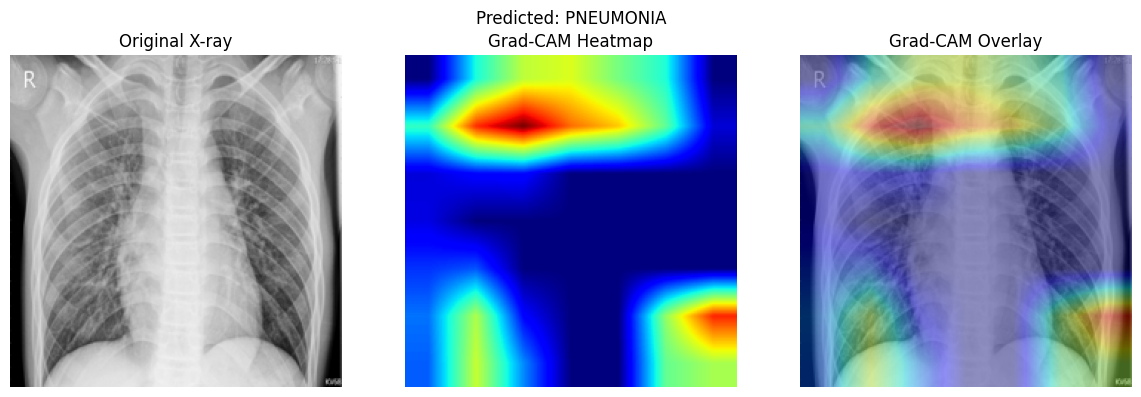

In [26]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load the best fine-tuned model
resnet.load_state_dict(
    torch.load(
        "/content/resnet18_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)
resnet.eval()

# Choose a test image
image_path = test_paths[0]
original_image = Image.open(image_path).convert("RGB")
input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

# Capture the final convolutional layer's activations and gradients
activations = None
gradients = None

def forward_hook(module, inputs, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

target_layer = resnet.layer4[-1].conv2
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

resnet.zero_grad()
output = resnet(input_tensor)
predicted_class = output.argmax(dim=1).item()

# Backpropagate the predicted class score
output[0, predicted_class].backward()

# Compute Grad-CAM heatmap
weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = (weights * activations).sum(dim=1, keepdim=True)
cam = F.relu(cam)
cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam[0, 0].detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() + 1e-8)

# Display original image and heatmap overlay
image_array = np.array(
    original_image.resize((224, 224))
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image_array)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Overlay")
plt.axis("off")

class_names = ["NORMAL", "PNEUMONIA"]
plt.suptitle(
    f"Predicted: {class_names[predicted_class]}"
)
plt.tight_layout()
plt.show()

forward_handle.remove()
backward_handle.remove()

In [27]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [28]:
import os
import shutil

save_dir = "/content/drive/MyDrive/Mini_Project_1_Results"
os.makedirs(save_dir, exist_ok=True)

files_to_save = [
    "/content/custom_cnn_best.pth",
    "/content/resnet18_feature_extractor.pth",
    "/content/resnet18_finetuned.pth"
]

for file_path in files_to_save:
    if os.path.exists(file_path):
        shutil.copy2(file_path, save_dir)

print("Available model checkpoints saved to:", save_dir)

Available model checkpoints saved to: /content/drive/MyDrive/Mini_Project_1_Results
